# One unit: 2D exc / inh RF debug

Run on **hhw9l84** with the rfmapping kernel. Load Unit 307 directly, compare
global and bottom-row references, then scan signed sigma values on the same map.
No detection sidecars or CSVs are written.

**bottom_row** uses one scalar baseline per unit: the mean of the entire last
stored spatial row. **Both references use the population SD of the entire 2D
spatial map.** Trial responses are not needed. Positive sigma selects increased
responses; negative sigma selects decreased responses relative to the reference.
These threshold masks do not establish permutation significance.


In [41]:
%matplotlib inline
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from RF.rflocate import load_rfmap, detect_rf
from Utils.plotting import apply_light_plot_style

apply_light_plot_style()
session = Path("/mnt/senzailab/Kai/#Recording/m22/261008/261008_2")
probe = "A"
unit_id = 256
time_range = (0.0, 0.2)  # Seconds; both references use the same response window.
sigma_exc = 2
sigma_inh = -1.15  # Matches the current locate_rf notebook; workflow default is -1.0.
drop_bins = 2     # Remove connected components containing <= 2 bins.
wrap_x = True
source = session / "data/rfmapping/good/-100_400_1ms" / f"Probe{probe}" / f"regular_unitsSpikeCounts_{session.name}.rfmap"


In [42]:
counts = load_rfmap(source).by_unit_id(unit_id)
rates = counts.to_firing_rate(reconstruct_presentations=True)
response = rates.mean_rate(*time_range)
values = response.to_2d_array()
n_y, n_x = values.shape
print(f"{session.name} / Probe{probe} / Unit {unit_id}; {time_range} s")
print(f"2D shape: {values.shape}; units: Hz; missing bins: {np.isnan(values).sum()}")
print("x positions:", response.x_positions)
print("y positions (stored row order):", response.y_positions)


261008_2 / ProbeA / Unit 256; (0.0, 0.2) s
2D shape: (7, 30); units: Hz; missing bins: 0
x positions: [-174. -162. -150. -138. -126. -114. -102.  -90.  -78.  -66.  -54.  -42.
  -30.  -18.   -6.    6.   18.   30.   42.   54.   66.   78.   90.  102.
  114.  126.  138.  150.  162.  174.]
y positions (stored row order): [-39. -27. -15.  -3.   9.  21.  33.]


In [43]:
exc_global = detect_rf(response, reference="global", sigma=sigma_exc,
                       drop_bins=drop_bins, wrap_x=wrap_x)
inh_global = detect_rf(response, reference="global", sigma=sigma_inh,
                       drop_bins=drop_bins, wrap_x=wrap_x)

global_values = np.where(np.isnan(values), 0.0, values)
global_mean = global_values.mean()
global_sd = global_values.std(ddof=0)
global_exc_threshold = global_mean + sigma_exc * global_sd
global_inh_threshold = global_mean + sigma_inh * global_sd
print(f"Global mean = {global_mean:.3f} Hz; spatial SD = {global_sd:.3f} Hz")
print(f"Exc: >= {global_exc_threshold:.3f} Hz; {exc_global.mask_2d.sum()} final bins")
print(f"Inh: <= {global_inh_threshold:.3f} Hz; {inh_global.mask_2d.sum()} final bins")


Global mean = 12.741 Hz; spatial SD = 3.438 Hz
Exc: >= 19.617 Hz; 8 final bins
Inh: <= 8.787 Hz; 8 final bins


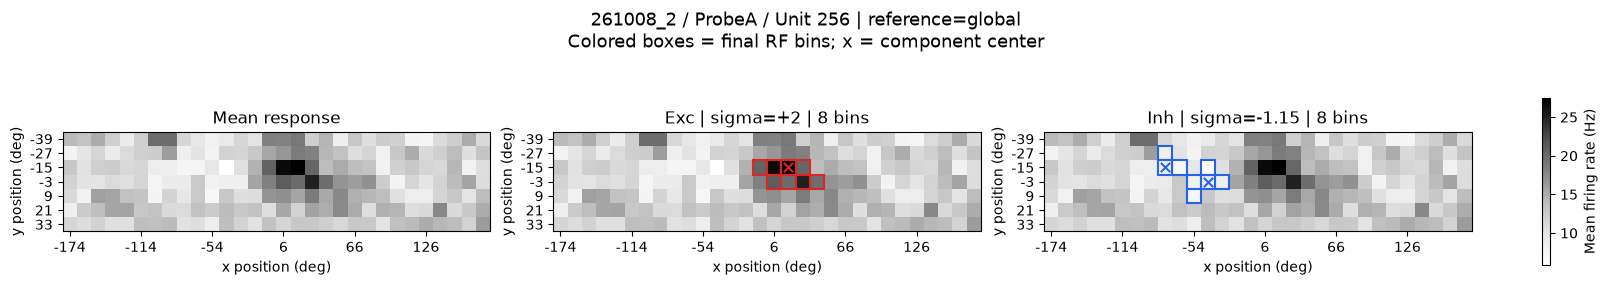

In [44]:
# This helper only draws supplied 2D data and masks; all detection calls are above/below.
def plot_detection(values, exc, inh, reference):
    fig, axes = plt.subplots(1, 3, figsize=(16, 3.0), layout="constrained")
    titles = ["Mean response", f"Exc | sigma={sigma_exc:+g} | {exc.mask_2d.sum()} bins",
              f"Inh | sigma={sigma_inh:+g} | {inh.mask_2d.sum()} bins"]
    for ax, title in zip(axes, titles):
        image = ax.imshow(values, cmap="Greys", origin="upper", interpolation="nearest",
                          vmin=np.nanmin(values), vmax=np.nanmax(values), aspect="equal")
        ax.set(title=title, xlabel="x position (deg)", ylabel="y position (deg)")
        columns = np.arange(0, n_x, 5)
        ax.set_xticks(columns, labels=[f"{x:g}" for x in response.x_positions[columns]])
        ax.set_yticks(np.arange(n_y), labels=[f"{y:g}" for y in response.y_positions])
    for ax, result, color in zip(axes[1:], [exc, inh], ["#dc2626", "#2563eb"]):
        for row, col in np.argwhere(result.mask_2d[0]):
            ax.add_patch(Rectangle((col - .5, row - .5), 1, 1,
                                   fill=False, edgecolor=color, linewidth=1.5))
        rows, cols = np.nonzero(result.center_2d[0])
        ax.scatter(cols, rows, marker="x", color=color, s=45)
    if reference == "bottom_row":
        axes[0].add_patch(Rectangle((-.5, n_y - 1.5), n_x, 1,
                                    fill=False, edgecolor="#d97706", linewidth=2))
    fig.colorbar(image, ax=axes, label="Mean firing rate (Hz)", shrink=.7)
    fig.suptitle(f"{session.name} / Probe{probe} / Unit {unit_id} | reference={reference}\n"
                 "Colored boxes = final RF bins; x = component center", fontsize=13)
    plt.show()
    return fig, axes

fig_global, axes_global = plot_detection(values, exc_global, inh_global, "global")


## Bottom-row mean with global spatial SD

Use the mean of all columns in the **last stored row** (orange box) as one
reference for this unit. The SD still comes from the full spatial map:

    baseline = response[-1, :].mean()
    sd = response.std(ddof=0)
    threshold = baseline + signed_sigma * sd

As in global detection, missing bins become zero before these statistics.
The last stored row is not necessarily the minimum numeric y coordinate.


In [5]:
bottom_mean = global_values[-1, :].mean()
bottom_exc_threshold = bottom_mean + sigma_exc * global_sd
bottom_inh_threshold = bottom_mean + sigma_inh * global_sd
print(f"Baseline row index: {n_y - 1}; stored y: {response.y_positions[-1]:g} deg")
print(f"Bottom-row mean = {bottom_mean:.3f} Hz; global spatial SD = {global_sd:.3f} Hz")
print(f"Exc threshold >= {bottom_exc_threshold:.3f} Hz; inh threshold <= {bottom_inh_threshold:.3f} Hz")


Baseline row index: 6; stored y: 33 deg
Bottom-row mean = 13.910 Hz; global spatial SD = 3.584 Hz
Exc threshold >= 20.360 Hz; inh threshold <= 12.118 Hz


Bottom-row final bins: exc=6, inh=16


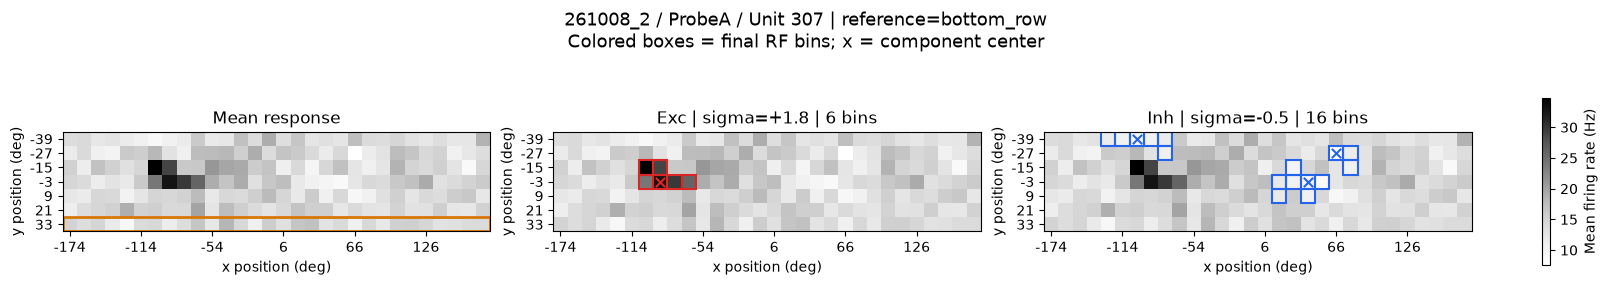

In [6]:
exc_bottom = detect_rf(response, reference="bottom_row", sigma=sigma_exc,
                       drop_bins=drop_bins, wrap_x=wrap_x)
inh_bottom = detect_rf(response, reference="bottom_row", sigma=sigma_inh,
                       drop_bins=drop_bins, wrap_x=wrap_x)
print(f"Bottom-row final bins: exc={exc_bottom.mask_2d.sum()}, inh={inh_bottom.mask_2d.sum()}")
fig_bottom, axes_bottom = plot_detection(values, exc_bottom, inh_bottom, "bottom_row")


## Reference levels and one column along Y

The two means shift the thresholds; the spatial SD is identical. Change
the column index below to inspect any column's response along Y, as in the sketch.


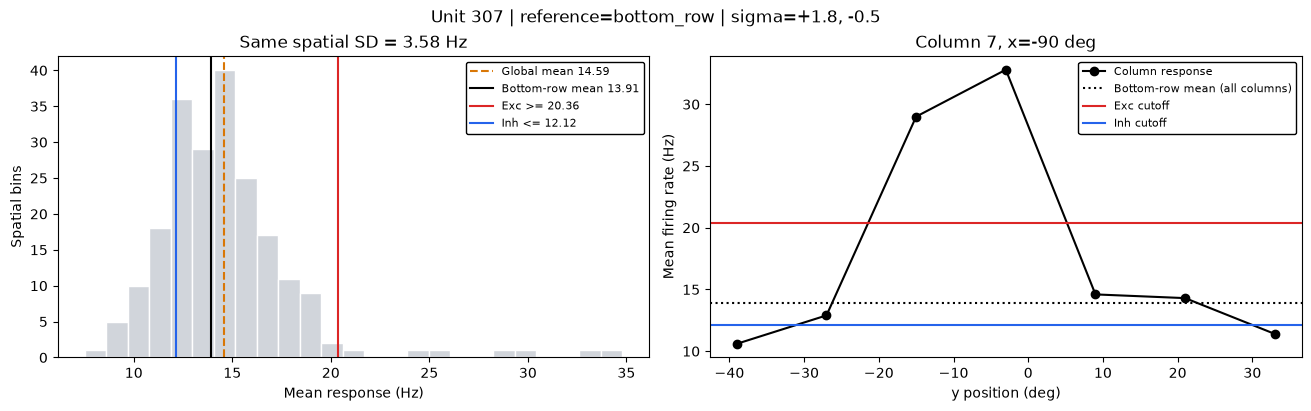

In [7]:
column = 7  # Zero-based column index; change this to inspect another vertical profile.
fig_thresholds, axes = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
axes[0].hist(global_values.ravel(), bins=25, color="#d1d5db", edgecolor="white")
axes[0].axvline(global_mean, color="#d97706", linestyle="--", label=f"Global mean {global_mean:.2f}")
axes[0].axvline(bottom_mean, color="black", label=f"Bottom-row mean {bottom_mean:.2f}")
axes[0].axvline(bottom_exc_threshold, color="#dc2626", label=f"Exc >= {bottom_exc_threshold:.2f}")
axes[0].axvline(bottom_inh_threshold, color="#2563eb", label=f"Inh <= {bottom_inh_threshold:.2f}")
axes[0].set(title=f"Same spatial SD = {global_sd:.2f} Hz", xlabel="Mean response (Hz)", ylabel="Spatial bins")
axes[1].plot(response.y_positions, global_values[:, column], "o-", color="black", label="Column response")
axes[1].axhline(bottom_mean, color="black", linestyle=":", label="Bottom-row mean (all columns)")
axes[1].axhline(bottom_exc_threshold, color="#dc2626", label="Exc cutoff")
axes[1].axhline(bottom_inh_threshold, color="#2563eb", label="Inh cutoff")
axes[1].set(title=f"Column {column}, x={response.x_positions[column]:g} deg",
            xlabel="y position (deg)", ylabel="Mean firing rate (Hz)")
for ax in axes:
    ax.legend(fontsize=8, frameon=True)
fig_thresholds.suptitle(f"Unit {unit_id} | reference=bottom_row | sigma={sigma_exc:+g}, {sigma_inh:+g}")
plt.show()


## Sigma scan on this unit

Only sigma changes below. Reference is bottom_row; time window, spatial SD,
drop_bins and wrap_x stay fixed. Each panel shows the final bins after component
filtering. The printed global count uses the same signed sigma for comparison.
This is a sensitivity check on one unit, not a population-wide choice of parameters.


Exc: signed sigma | cutoff Hz | candidate bins | final bins | global final bins
 +0.50 |   15.70 |  56 |  41 |  30
 +1.00 |   17.49 |  29 |  17 |  11
 +1.50 |   19.29 |  11 |   9 |   6
 +1.80 |   20.36 |   7 |   6 |   6
 +2.00 |   21.08 |   6 |   6 |   6
 +2.50 |   22.87 |   6 |   6 |   6
 +3.00 |   24.66 |   5 |   5 |   5


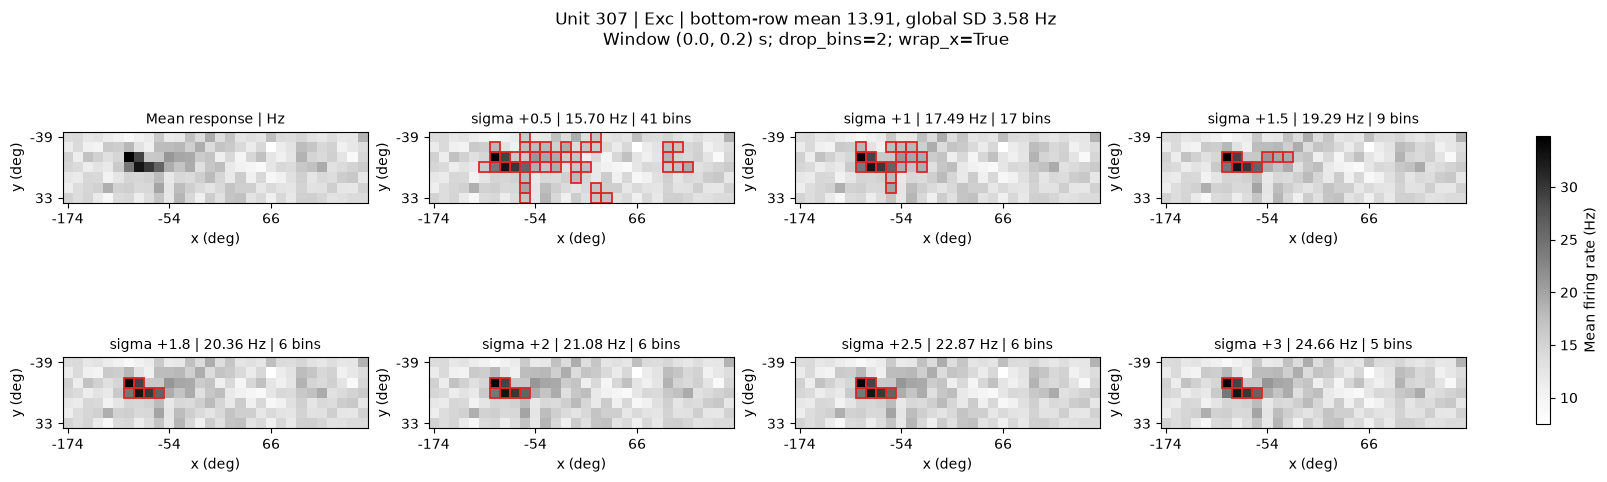

Inh: signed sigma | cutoff Hz | candidate bins | final bins | global final bins
 -0.25 |   13.01 |  71 |  48 |  68
 -0.50 |   12.12 |  42 |  16 |  47
 -0.75 |   11.22 |  23 |   8 |  16
 -1.00 |   10.33 |   9 |   0 |   8
 -1.25 |    9.43 |   6 |   0 |   0
 -1.50 |    8.53 |   1 |   0 |   0
 -2.00 |    6.74 |   0 |   0 |   0


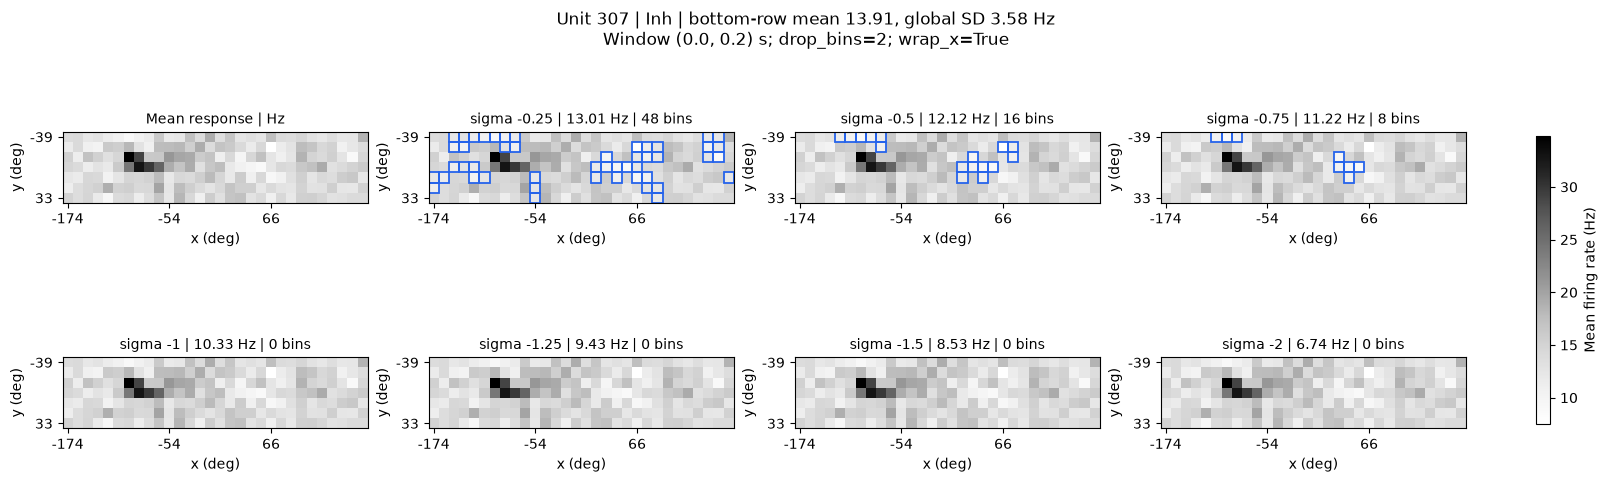

In [8]:
sigma_grid = {
    "Exc": [0.5, 1.0, 1.5, 1.8, 2.0, 2.5, 3.0],
    "Inh": [-0.25, -0.5, -0.75, -1.0, -1.25, -1.5, -2.0],
}
sweep_results = {}
for label, sigmas in sigma_grid.items():
    color = "#dc2626" if label == "Exc" else "#2563eb"
    fig, axes = plt.subplots(2, 4, figsize=(16, 5), layout="constrained")
    axes = axes.ravel()
    for ax in axes:
        image = ax.imshow(values, cmap="Greys", origin="upper", interpolation="nearest",
                          vmin=np.nanmin(values), vmax=np.nanmax(values), aspect="equal")
        columns = np.arange(0, n_x, 10)
        ax.set_xticks(columns, labels=[f"{x:g}" for x in response.x_positions[columns]])
        ax.set_yticks([0, n_y - 1], labels=[f"{y:g}" for y in response.y_positions[[0, -1]]])
        ax.set(xlabel="x (deg)", ylabel="y (deg)")
    axes[0].set_title("Mean response | Hz", fontsize=10)
    print(f"{label}: signed sigma | cutoff Hz | candidate bins | final bins | global final bins")
    for ax, sigma in zip(axes[1:], sigmas):
        result = detect_rf(response, reference="bottom_row", sigma=sigma,
                           drop_bins=drop_bins, wrap_x=wrap_x)
        global_result = detect_rf(response, reference="global", sigma=sigma,
                                  drop_bins=drop_bins, wrap_x=wrap_x)
        cutoff = bottom_mean + sigma * global_sd
        candidate = global_values >= cutoff if sigma > 0 else global_values <= cutoff
        sweep_results[sigma] = result
        for row, col in np.argwhere(result.mask_2d[0]):
            ax.add_patch(Rectangle((col - .5, row - .5), 1, 1,
                                   fill=False, edgecolor=color, linewidth=1.3))
        ax.set_title(f"sigma {sigma:+g} | {cutoff:.2f} Hz | {result.mask_2d.sum()} bins", fontsize=10)
        print(f"{sigma:+6.2f} | {cutoff:7.2f} | {candidate.sum():3d} | {result.mask_2d.sum():3d} | {global_result.mask_2d.sum():3d}")
    fig.colorbar(image, ax=axes, label="Mean firing rate (Hz)", shrink=.65)
    fig.suptitle(f"Unit {unit_id} | {label} | bottom-row mean {bottom_mean:.2f}, global SD {global_sd:.2f} Hz\n"
                 f"Window {time_range} s; drop_bins={drop_bins}; wrap_x={wrap_x}")
    plt.show()
